# What are the Giller nominees' star signs?

Are Giller-nominated novelists more likely to be Virgos than Leos? Astrology is not a science, and we're not going to find out whether the stars make writers. But the question is a good excuse to practise something every data project needs: deciding **when we have enough information** to answer a question, and being honest about the rows we have to leave out.

An astrological (sun) sign depends on the **month and day** someone was born. Our spreadsheet's `DOB` column has that for some authors, only a year or a month for others, and nothing at all for the rest. In this notebook we will:

1. clean up the author names and dates of birth;
2. keep only the authors whose **full** date of birth we know;
3. write a function that turns a month and day into a sign;
4. count and chart the signs, and ask whether the pattern means anything.

## 1. Loading the data

This time we start from the original spreadsheet, `giller_nominees.csv`, which has one row per nominated **book**.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

books = pd.read_csv("giller_nominees.csv")

print(len(books), "nominated books")
books.columns

313 nominated books


Index(['Status', 'Year ', 'Title ', 'Author ', 'Publisher ',
       'Publisher Location ', 'Born ', 'DOB', 'Residence ', 'DOD', 'Bio',
       'Novel'],
      dtype='object')

Look closely at the column names: several of them end with a space, like `'Author '`. That means `books["Author"]` wouldn't work, because there's no column with exactly that name! The column names behave like a column of strings, so `.str.strip()` removes the extra spaces from all of them at once.

In [19]:
books.columns = books.columns.str.strip()

books = books[["Status", "Year", "Author", "DOB"]]
books.head()

,Status,Year,Author,DOB
0,short-listed,1996,Ann-Marie MacDonald,29/10/1958
1,short-listed,1997,Carol Shields,02/06/1935
2,winner,1997,Mordecai Richler,27/01/1931
3,short-listed,1998,Wayne Johnston,22/05/1958
4,short-listed,1999,David Macfarlane,00/00/1952


## 2. Cleaning up the author names

The same stray spaces appear inside the cells, too: `"Carol Shields "` and `"Carol Shields"` would count as two different authors. And translated novels list the translator in the same cell, like `"Kim Thúy, translated by Sheila Fischman"`. Kim Thúy's star sign is what we want, not her translator's.

Splitting each name at the comma and keeping the first piece (`.str[0]`) leaves only the author. Then `.str.strip()` removes the extra spaces. We clean up the `Status` and `DOB` columns' spaces in the same way.

In [20]:
books["Author"] = books["Author"].str.split(",").str[0].str.strip()
books["Status"] = books["Status"].str.strip()
books["DOB"] = books["DOB"].str.strip()

books[books["Author"] == "Kim Thúy"]

,Status,Year,Author,DOB
270,short-listed,2012,Kim Thúy,1968
284,long-listed,2018,Kim Thúy,1968
289,long-listed,2021,Kim Thúy,1968


## 3. Which dates of birth are good enough?

To find a sign we need the month **and** the day. Here is every way a date is written in the `DOB` column:

| Example | What we know | Enough for a sign? |
|---|---|---|
| `29/10/1958` | day, month, and year | yes |
| `5/11/1983` | the same, with a one-digit day | yes |
| `10/1969` | month and year only | no: October is partly Libra and partly Scorpio |
| `1979` | year only | no |
| `-` | nothing | no |
| `00/00/1952` | `00` is a placeholder: year only | no |
| `04-Apr-43`, `Oct-69` | Excel changed these: see below | it depends |

The dates are written **day/month/year**, the usual order in Canada and the UK. We can tell because many of them start with a number bigger than 12, like `29/10/1958`, and there is no 29th month.

### Fixing values with a dictionary

As in the age notebook, two authors' dates were changed by Excel. Paulette Jiles was born on April 4, 1943, so we can fix her date. Emma Donoghue's other rows say `10/1969`, which is only a month, so her date won't be good enough either way.

In [21]:
dob_corrections = {
    "04-Apr-43": "04/04/1943",   # Paulette Jiles
    "Oct-69": "10/1969",         # Emma Donoghue
}

books["DOB"] = books["DOB"].replace(dob_corrections)

### Keeping only full dates

A full date has **three** pieces when we split it at each `/`. A month and year has two, and a year on its own has one. `.str.len()` tells us how many pieces are in each list, so we can keep the rows with exactly three.

In [22]:
dob_pieces = books["DOB"].str.split("/")
dob_pieces.str.len().value_counts()

DOB
3    173
1    136
2      4
Name: count, dtype: int64

In [23]:
full_dates = books[dob_pieces.str.len() == 3].copy()

full_dates["Day"] = full_dates["DOB"].str.split("/").str[0].astype(int)
full_dates["Month"] = full_dates["DOB"].str.split("/").str[1].astype(int)

full_dates.head()

,Status,Year,Author,DOB,Day,Month
0,short-listed,1996,Ann-Marie MacDonald,29/10/1958,29,10
1,short-listed,1997,Carol Shields,02/06/1935,2,6
2,winner,1997,Mordecai Richler,27/01/1931,27,1
3,short-listed,1998,Wayne Johnston,22/05/1958,22,5
4,short-listed,1999,David Macfarlane,00/00/1952,0,0


The `00/00/1952` placeholder has three pieces too, but a day or month of `0` means "unknown". We remove those rows as well.

In [24]:
full_dates[(full_dates["Day"] == 0) | (full_dates["Month"] == 0)]

,Status,Year,Author,DOB,Day,Month
4,short-listed,1999,David Macfarlane,00/00/1952,0,0


In [25]:
full_dates = full_dates[(full_dates["Day"] != 0) & (full_dates["Month"] != 0)].copy()

(`&` means "and": keep a row only if *both* conditions are true.)

### One row per author

Many authors were nominated more than once, but each author has only one star sign. `.drop_duplicates("Author")` keeps the first row for each author.

The order of these steps matters. We picked out the full dates **before** removing duplicates, so if an author's date was complete in one row but not in another, we keep the complete one.

In [26]:
authors = full_dates.drop_duplicates("Author").copy()

all_authors = books["Author"].nunique()
print(all_authors, "authors in the spreadsheet")
print(len(authors), "authors with a full date of birth")
print(all_authors - len(authors), "authors left out because we don't know their birthday")

218 authors in the spreadsheet
104 authors with a full date of birth
114 authors left out because we don't know their birthday


We can only answer our question for fewer than half of the authors. Keep that in mind when we look at the results.

## 4. From a date to a star sign

Each sign covers a stretch of the calendar, for example Aries runs from March 21 to April 19. Comparing two numbers (month and day) at once is fiddly, so here's a trick: combine them into **one** number, `month × 100 + day`. March 21 becomes `321`, April 19 becomes `419`, and October 29 becomes `1029`.

These numbers are in calendar order. Every date in March is between `301` and `331`, every date in April is between `401` and `430`, and so on. So "is this date before April 20?" becomes a simple `<` comparison.

In [27]:
authors["Month and day"] = authors["Month"] * 100 + authors["Day"]

authors[["Author", "DOB", "Month and day"]].head()

,Author,DOB,Month and day
0,Ann-Marie MacDonald,29/10/1958,1029
1,Carol Shields,02/06/1935,602
2,Mordecai Richler,27/01/1931,127
3,Wayne Johnston,22/05/1958,522
8,Miriam Toews,21/05/1964,521


Now a function with `if`/`elif` can work through the calendar. The first test that is true decides the sign, so each `elif` only has to check where the *next* sign begins.

Capricorn wraps around the new year (December 22 to January 19), which is why it appears at both the start and the end.

In [28]:
def zodiac_sign(month_and_day):
    """ Return the astrological sign for month_and_day, a date written as
        month * 100 + day (so October 29 is 1029).
    """
    if month_and_day < 120:
        return "Capricorn"
    elif month_and_day < 219:
        return "Aquarius"
    elif month_and_day < 321:
        return "Pisces"
    elif month_and_day < 420:
        return "Aries"
    elif month_and_day < 521:
        return "Taurus"
    elif month_and_day < 621:
        return "Gemini"
    elif month_and_day < 723:
        return "Cancer"
    elif month_and_day < 823:
        return "Leo"
    elif month_and_day < 923:
        return "Virgo"
    elif month_and_day < 1023:
        return "Libra"
    elif month_and_day < 1122:
        return "Scorpio"
    elif month_and_day < 1222:
        return "Sagittarius"
    else:
        return "Capricorn"

Always test a function on examples you can check by hand, especially at the edges, where one sign ends and the next begins:

In [29]:
print(zodiac_sign(1029))   # October 29: Scorpio
print(zodiac_sign(321))    # March 21, the first day of Aries
print(zodiac_sign(320))    # March 20, the last day of Pisces
print(zodiac_sign(1225))   # December 25: Capricorn
print(zodiac_sign(105))    # January 5: also Capricorn

Scorpio
Aries
Pisces
Capricorn
Capricorn


### Using a function with `.map()`

We've used `.map()` with a dictionary, to look up each value. **New this time:** `.map()` can also take a *function*. It calls the function once for every value in the column and collects what comes back. Notice that we write `zodiac_sign` without parentheses: we're handing the function itself to `.map()`, which does the calling.

In [30]:
authors["Sign"] = authors["Month and day"].map(zodiac_sign)

authors[["Author", "DOB", "Sign"]].sort_values("Author").head(15)

,Author,DOB,Sign
51,Adam Foulds,08/10/1974,Libra
98,Alan Cumyn,08/01/1967,Capricorn
11,Alexi Zentner,29/08/1973,Virgo
204,Alice Munro,10/07/1931,Cancer
166,Alix Ohlin,04/05/1972,Taurus
68,André Alexis,15/01/1957,Capricorn
50,Andrée A. Michaud,12/11/1957,Scorpio
0,Ann-Marie MacDonald,29/10/1958,Scorpio
160,Anne Hébert,01/08/1916,Leo
26,Anne Michaels,15/04/1958,Aries


## 5. Counting the signs

`.value_counts()` counts how many authors have each sign. It sorts the counts from most to least, but a reader expects the signs in their usual order, Aries to Pisces. As in an earlier notebook, `.loc[]` with a list gives us the rows in the order we choose.

In [31]:
signs_in_order = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo",
                  "Libra", "Scorpio", "Sagittarius", "Capricorn", "Aquarius", "Pisces"]

sign_counts = authors["Sign"].value_counts().loc[signs_in_order]
sign_counts

Sign
Aries           9
Taurus         11
Gemini         12
Cancer          6
Leo             5
Virgo          13
Libra          10
Scorpio         9
Sagittarius     2
Capricorn      12
Aquarius        9
Pisces          6
Name: count, dtype: int64

### Compared to what?

A count means little on its own. If signs had nothing to do with becoming a Giller nominee, we'd expect about the same number of authors for each one: the total divided by 12. We draw that **expected** value as a line, so a reader can see which signs are above or below it.

`ax.invert_yaxis()` flips the chart so that Aries is at the top and the list reads downward, like a horoscope column. In `ax.text()`, `ha="right"` lines the label up so that it *ends* just left of the line, and `8` places it on the ninth row (counting from 0), beside the short Sagittarius bar where there is empty space.

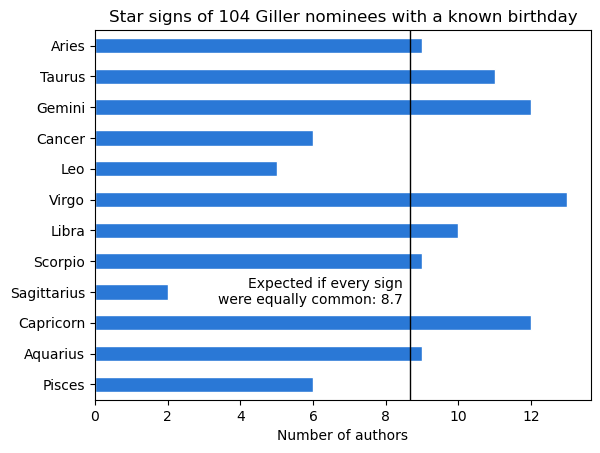

In [32]:
expected = len(authors) / 12

ax = sign_counts.plot.barh(color="#2a78d6", edgecolor="white")
ax.invert_yaxis()

ax.axvline(expected, color="black", linewidth=1)
ax.text(expected - 0.2, 8, f"Expected if every sign\nwere equally common: {expected:.1f}",
        ha="right", va="center")

ax.set_title(f"Star signs of {len(authors)} Giller nominees with a known birthday")
ax.set_xlabel("Number of authors")
ax.set_ylabel("")
plt.show()

Virgo comes out on top, with Gemini and Capricorn close behind, and Sagittarius has only 2 authors. Before we write the horoscope headline ("Virgos: your Giller year is coming!"), it's worth asking whether we'd see bumps like these **by chance alone**.

Think of flipping a coin 10 times: you won't always get exactly 5 heads, and 7 heads isn't evidence that the coin is rigged. With only 104 authors spread over 12 signs, each sign gets about 8 or 9, and small groups like that bounce around a lot. A difference of a few authors either way is just what chance looks like at this size.

## 6. What about the winners?

The `Status` column tells us which books won. A few winners tied, so the status is either `"winner"` or `"winner (tie)"`.

In [33]:
winners = full_dates[(full_dates["Status"] == "winner") | (full_dates["Status"] == "winner (tie)")]
winners = winners.drop_duplicates("Author").copy()

winners["Month and day"] = winners["Month"] * 100 + winners["Day"]
winners["Sign"] = winners["Month and day"].map(zodiac_sign)

print(len(winners), "winners with a full date of birth")
winners[["Year", "Author", "DOB", "Sign"]].sort_values("Year")

21 winners with a full date of birth


,Year,Author,DOB,Sign
201,1994,M.G. Vassanji,30/05/1950,Gemini
203,1996,Margaret Atwood,18/11/1939,Scorpio
2,1997,Mordecai Richler,27/01/1931,Aquarius
204,1998,Alice Munro,10/07/1931,Cancer
123,1999,Bonnie Burnard,15/01/1945,Capricorn
244,2000,David Adams Richards,17/10/1950,Libra
206,2000,Michael Ondaatje,12/09/1943,Virgo
125,2001,Richard B. Wright,04/03/1937,Pisces
302,2002,Austin Clarke,26/07/1934,Leo
211,2005,David Bergen,14/01/1957,Capricorn


In [34]:
winners["Sign"].value_counts()

Sign
Virgo        3
Capricorn    3
Gemini       3
Libra        3
Aquarius     2
Scorpio      2
Taurus       1
Aries        1
Pisces       1
Cancer       1
Leo          1
Name: count, dtype: int64

**Discussion:**
- We left out more than half of the authors. Which authors are most likely to be missing an exact birthday on Wikipedia and in other sources? Could leaving them out change which signs look common?
- Sign dates shift by a day from year to year, so an author born on the very edge of a sign (a "cusp") might be counted differently by an astrologer. Find an author in our table born within a day of a boundary. Does it matter for our conclusions?
- Births aren't spread perfectly evenly across the year: in Canada, more babies are born in some months than others. How would that affect the "expected" line? Is "equally common" the right comparison?
- Suppose Virgos had come out far ahead, with 30 authors. Would that show that astrology works? What else could explain it?

## 7. Try it yourself

1. Change the chart's title so that it states what you think the chart shows, the way a newspaper headline would.
2. Which **month** of birth is most common among the nominees? Use the `Month` column and `.value_counts()`. Is the pattern the same as for the signs?
3. Find all the authors who share a sign with you. Have you read any of their books?
4. Write a function `element(sign)` that returns the sign's traditional element: `"Fire"` (Aries, Leo, Sagittarius), `"Earth"` (Taurus, Virgo, Capricorn), `"Air"` (Gemini, Libra, Aquarius), or `"Water"` (Cancer, Scorpio, Pisces). Use `.map()` to add an `Element` column to `authors`, and count the authors in each element. With about 26 authors expected per element, does the pattern look any less like chance?
5. **Challenge:** Using `books`, find the authors who have a year of birth but **not** a full date. These are the authors whose sign we could look up if we found better sources. Pick one and try to find their birthday.